In [5]:
import numpy as np
import pandas as pd
import pickle
import gzip
import matplotlib.pyplot as plt

# Sklearn per classificazione classica post-trasformazione
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.model_selection import train_test_split

# Libreria aeon per Time Series Classification con Shapelet
from aeon.classification.shapelet_based import RDSTClassifier
from aeon.transformations.collection.shapelet_based import RandomShapeletTransform


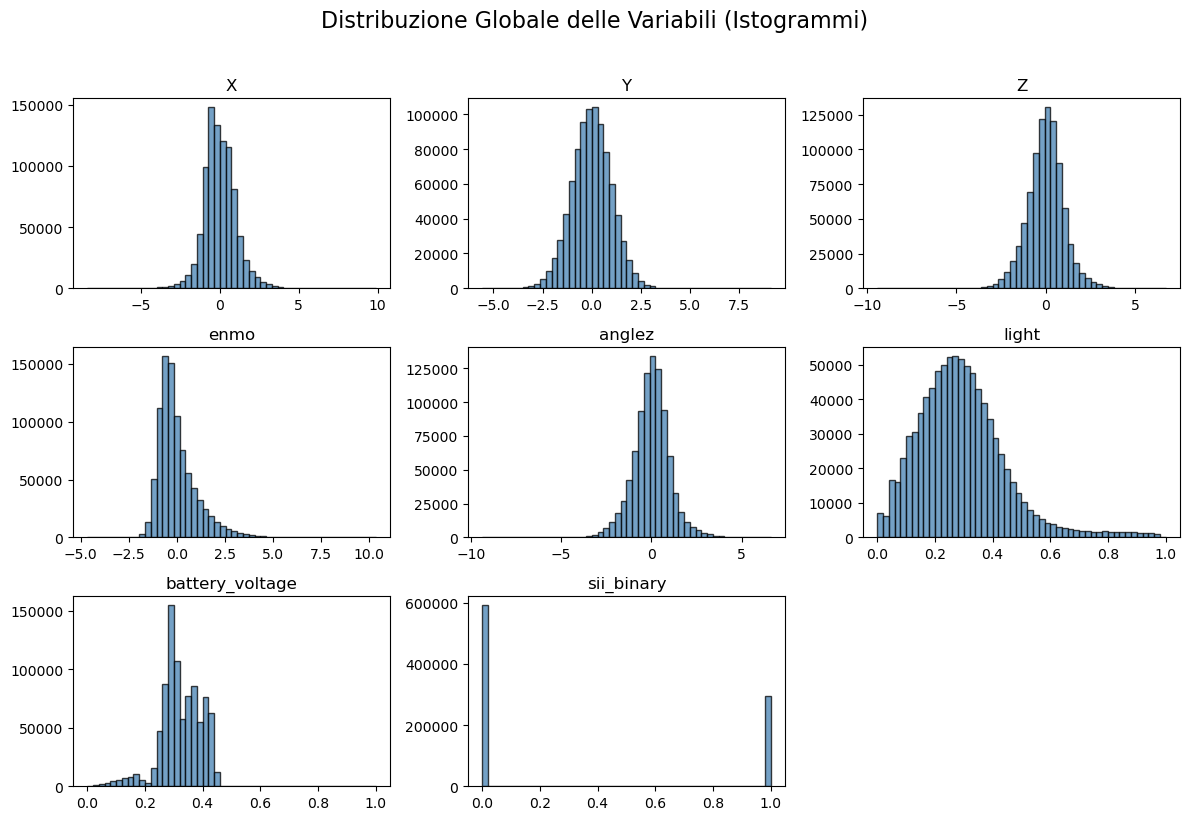

In [6]:
with gzip.open("ts_normalized.pkl.gz", "rb") as f:
    ts = pickle.load(f)

for df in ts:
    if 'id' in df.columns:
        df.drop(columns=['id'], inplace=True)  # inutile
    if 'non-wear_flag' in df.columns:
        df.drop(columns=['non-wear_flag'], inplace=True)
    if 'weekday' in df.columns:
        df.drop(columns=['weekday'], inplace=True)
    if 'quarter' in df.columns:
        df.drop(columns=['quarter'], inplace=True)
    if 'relative_date_PCIAT' in df.columns:
        df.drop(columns=['relative_date_PCIAT'], inplace=True)

ts_globale = pd.concat(ts, ignore_index=True)

# Opzionale: campionamento per velocizzare la generazione grafica in caso di dataset massivi.
# Se si desidera analizzare il 100% dei dati, lasciare frac=1.0.
df_plot = ts_globale.sample(frac=1.0, random_state=222)

# ==========================================
# 3. Visualizzazione tramite Istogrammi
# ==========================================
# Viene creata una griglia automatica in base al numero di colonne
df_plot.hist(bins=50, figsize=(12, 8), edgecolor='black',
             grid=False, alpha=0.75, color='steelblue')
plt.suptitle("Distribuzione Globale delle Variabili (Istogrammi)",
             y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

### Fase A: Preparazione dei dati per aeon e Shapelet Transform

In [7]:
# Usiamo la variabile ENMO come feature principale per gli shapelet.
X = [df['enmo'].values for df in ts]
# Estraiamo l'etichetta globale per ogni soggetto
y = np.array([df['sii_binary'].iloc[0] for df in ts])

# Splittiamo in Train e Test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=222, stratify=y)

print(f"Numero di serie in Train: {len(X_train)}")
print(f"Numero di serie in Test: {len(X_test)}")

Numero di serie in Train: 3105
Numero di serie in Test: 1332


### Estrazione degli Shapelet

### Addestramento e Ottimizzazione (Pipeline: Shapelet + Decision Tree)

Ogni singolo shapelet estratto calcola sempre 3 parametri (feature) distinti:

1. Min (Distanza Minima): Quanto la firma comportamentale somiglia alla curva del paziente.
2. Argmin (Posizione Temporale): Quando (in quale tick) si verifica quella firma all'interno della giornata.
3. SO (Shapelet Occurrence): Quante volte quella firma si ripete durante tutta l'acquisizione (la frequenza).

L'algoritmo estrae 1000 shapelet in modo totalmente casuale (con varie lunghezze e dilatazioni).
Genera per ognuno di essi 3 distanze (creando quindi una gigantesca tabella con 3000 colonne/feature).
Se li tiene tutti. Non ne scarta nessuno. Passa questa tabella mastodontica direttamente al Modello di Machine Learning (nel nostro caso, il DecisionTreeClassifier che gli abbiamo impostato noi, oppure il Ridge di default).
Perché lo fa?
L'RDST è progettato con una filosofia moderna: invece di sprecare tempo prezioso a calcolare quale shapelet è buono e quale è scarso prima dell'addestramento, passa tutto il blocco di dati al classificatore. Sarà poi il DecisionTreeClassifier (durante il suo fit) a fare tutto il lavoro sporco: quando costruirà l'albero, analizzerà le 3.000 colonne, scarterà automaticamente le 2.999 feature inutili (non mettendole in nessun nodo) e piazzerà il "miglior shapelet assoluto" in cima, al nodo radice.

Quindi, aumentando max_shapelets=5000 o 10000, non andrai a sovraccaricare il risultato finale (l'albero farà sempre e solo i suoi split mirati), ma darai semplicemente al modello un "paniere" di candidati molto più grande tra cui trovare il micro-movimento perfetto!

Inizio Addestramento con RDSTClassifier + DecisionTree...
=== REPORT DI CLASSIFICAZIONE ===
               precision    recall  f1-score   support

Basso Rischio       0.68      0.91      0.78       888
 Alto Rischio       0.47      0.16      0.24       444

     accuracy                           0.66      1332
    macro avg       0.58      0.53      0.51      1332
 weighted avg       0.61      0.66      0.60      1332



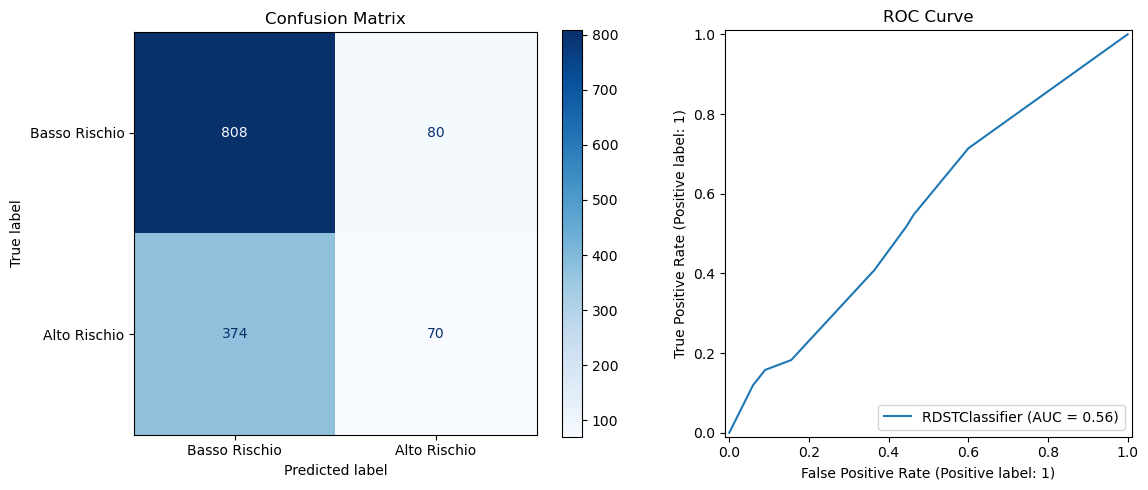

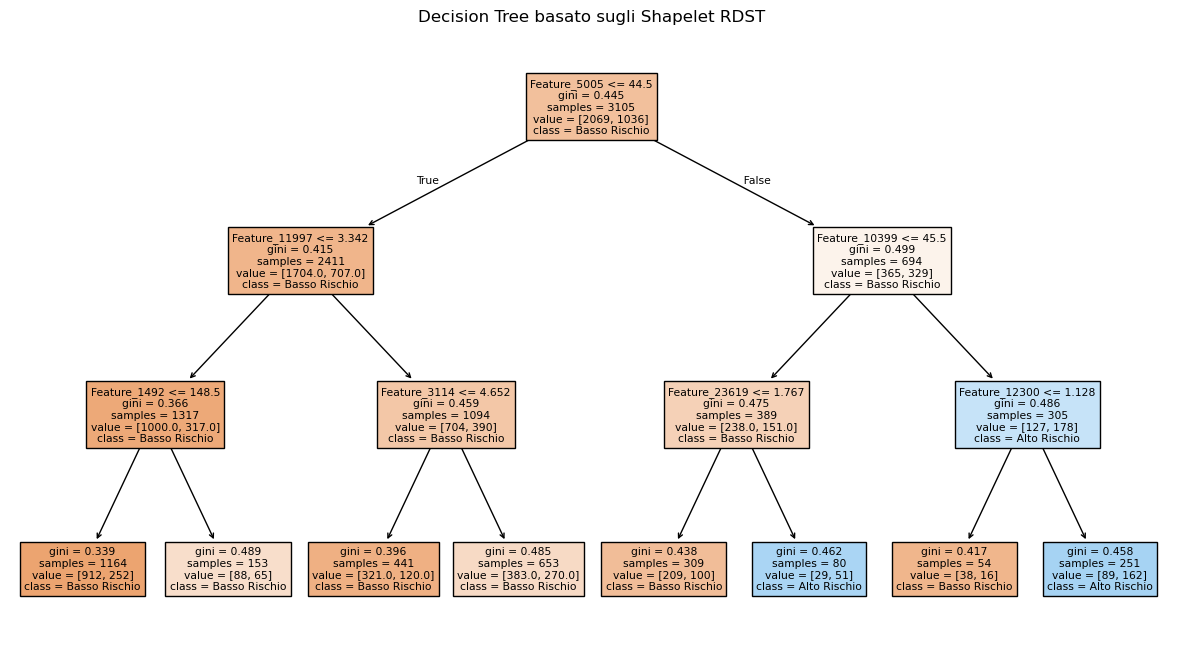

La feature più discriminante è la n° 5005, associata allo shapelet 1668


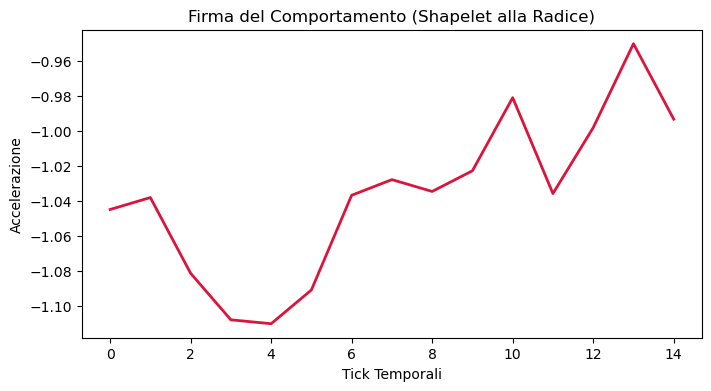

In [8]:
print("Inizio Addestramento con RDSTClassifier + DecisionTree...")
# Inizializziamo il classificatore, 
# ma cambiamo il "motore" interno con un Decision Tree per poterlo osservare come richiesto!
dt = DecisionTreeClassifier(max_depth=3, random_state=222)
clf = RDSTClassifier(max_shapelets=10000, estimator=dt, random_state=222, n_jobs=-1, shapelet_lengths=[10,11,15], use_prime_dilations=True, save_transformed_data=True, class_weight='balanced_subsample')

'''use_prime_dilations (default: False)
Cosa fa: Se lo metti a True, l'algoritmo userà solo numeri primi per calcolare gli "spazi" di dilatazione tra un punto e l'altro del pattern.
Come sceglierlo: Mettilo a True. Riduce drasticamente i calcoli inutili e la ridondanza, velocizzando il processo senza perdere praticamente nulla in accuratezza.'''

# RDST fa l'estrazione e poi addestra l'albero
clf.fit(X_train, y_train)

# Previsioni
y_pred = clf.predict(X_test)

print("=== REPORT DI CLASSIFICAZIONE ===")
print(classification_report(y_test, y_pred, target_names=["Basso Rischio", "Alto Rischio"]))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_estimator(clf, X_test, y_test, 
                                      display_labels=["Basso Rischio", "Alto Rischio"], 
                                      cmap="Blues", ax=ax1)
ax1.set_title("Confusion Matrix")

RocCurveDisplay.from_estimator(clf, X_test, y_test, ax=ax2)
ax2.set_title("ROC Curve")

plt.tight_layout()
plt.show()

# =======================================================
# ESTRAZIONE DELL'ALBERO E DELLO SHAPELET ALLA RADICE
# =======================================================
best_dt = clf._estimator

plt.figure(figsize=(15, 8))
plot_tree(best_dt, filled=True, 
          feature_names=[f"Feature_{i}" for i in range(best_dt.n_features_in_)],
          class_names=["Basso Rischio", "Alto Rischio"])
plt.title("Decision Tree basato sugli Shapelet RDST")
plt.show()

try:
    # L'indice della feature usata nel primo split (nodo radice)
    root_feature_idx = best_dt.tree_.feature[0]
    
    # In RDST, l'estrattore genera tipicamente 3 feature per ogni shapelet (es. minima distanza, posizione, ecc.)
    # L'indice reale dello shapelet nell'array è quindi feature_idx // 3
    num_shapelets = clf._transformer.shapelets_[0].shape[0]
    shapelet_array_idx = root_feature_idx // (best_dt.n_features_in_ // num_shapelets)
    
    print(f"La feature più discriminante è la n° {root_feature_idx}, associata allo shapelet {shapelet_array_idx}")
    
    best_shapelet = clf._transformer.shapelets_[0][shapelet_array_idx][0]
    
    plt.figure(figsize=(8, 4))
    plt.plot(best_shapelet, color='crimson', linewidth=2)
    plt.title(f"Firma del Comportamento (Shapelet alla Radice)")
    plt.xlabel("Tick Temporali")
    plt.ylabel("Accelerazione")
    plt.show()
    
    shapelet_fase_b = best_shapelet
except Exception as e:
    print("Non è stato possibile estrarre la forma grezza per il plot. Errore:", e)
    shapelet_fase_b = None


L'albero decisionale, guardando tutte le 3000 colonne fornite da RDST, ha deciso che la colonna numero 514 è in assoluto la migliore per dividere i pazienti ad "Alto Rischio" da quelli a "Basso Rischio".

Facendo un rapido calcolo matematico: 514÷3=171 (con resto di 1). Questo ci dice due cose fondamentali da scrivere nel report:

L'albero ha scelto la "forma" dello Shapelet numero 171 (tra i 1000 generati casualmente) come la più importante. È quella che vedi disegnata nel grafico in basso.
Il resto di 1 ci indica quale delle 3 feature di quello shapelet ha usato per il taglio:
Resto 0 = Distanza
Resto 1 = Posizione Temporale (Argmin)
Resto 2 = Frequenza (Occurrence)
Conclusione: Il modello ha scoperto che non è tanto importante se il paziente fa quel movimento, o quanto spesso lo fa, ma è IL MOMENTO in cui lo fa (la sua posizione nel tempo) a essere il fattore più discriminante per l'Alto Rischio di dipendenza!

## Fase B: Il Ponte d'Oro (Shapelets vs Motifs vs Discords)

--- FASE B: Confronto Globale vs Locale ---
Lunghezza Shapelet (Globale) e Finestra Matrix Profile (Locale): m=15



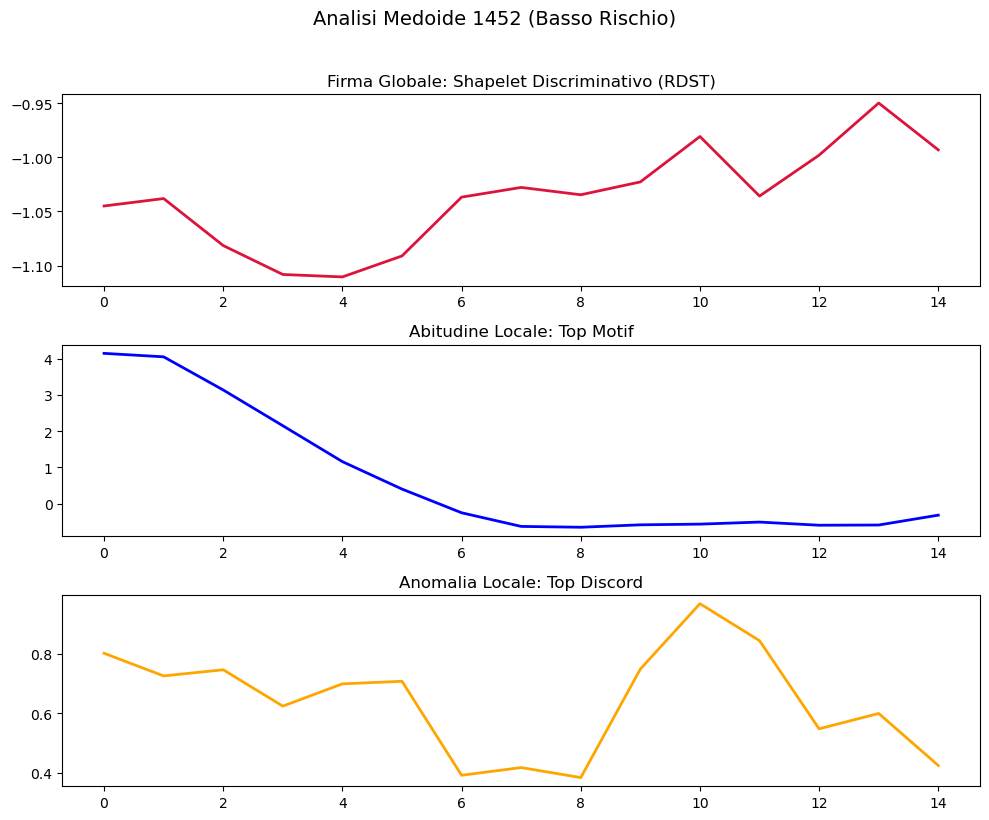

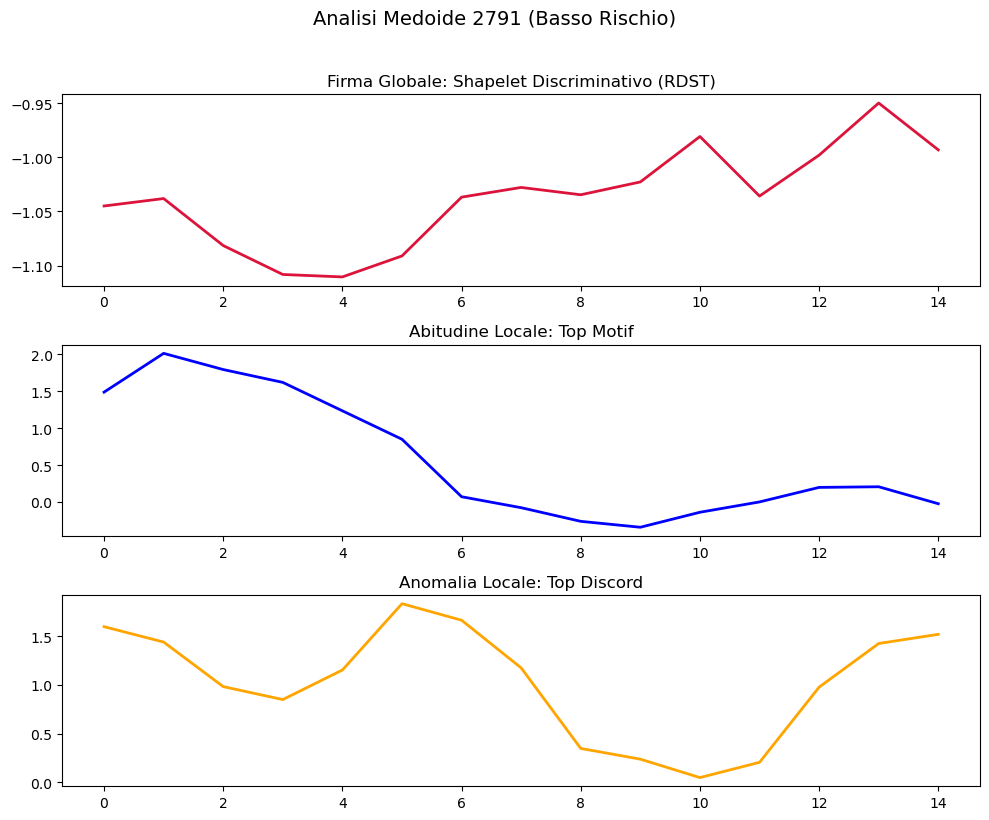

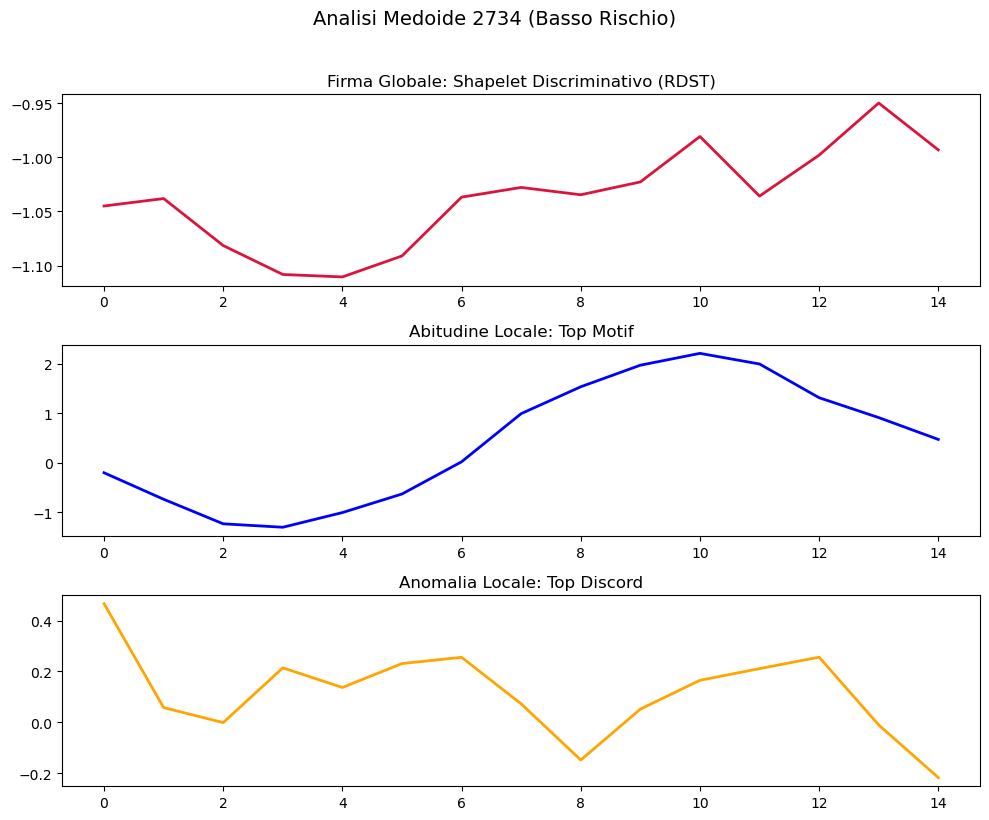

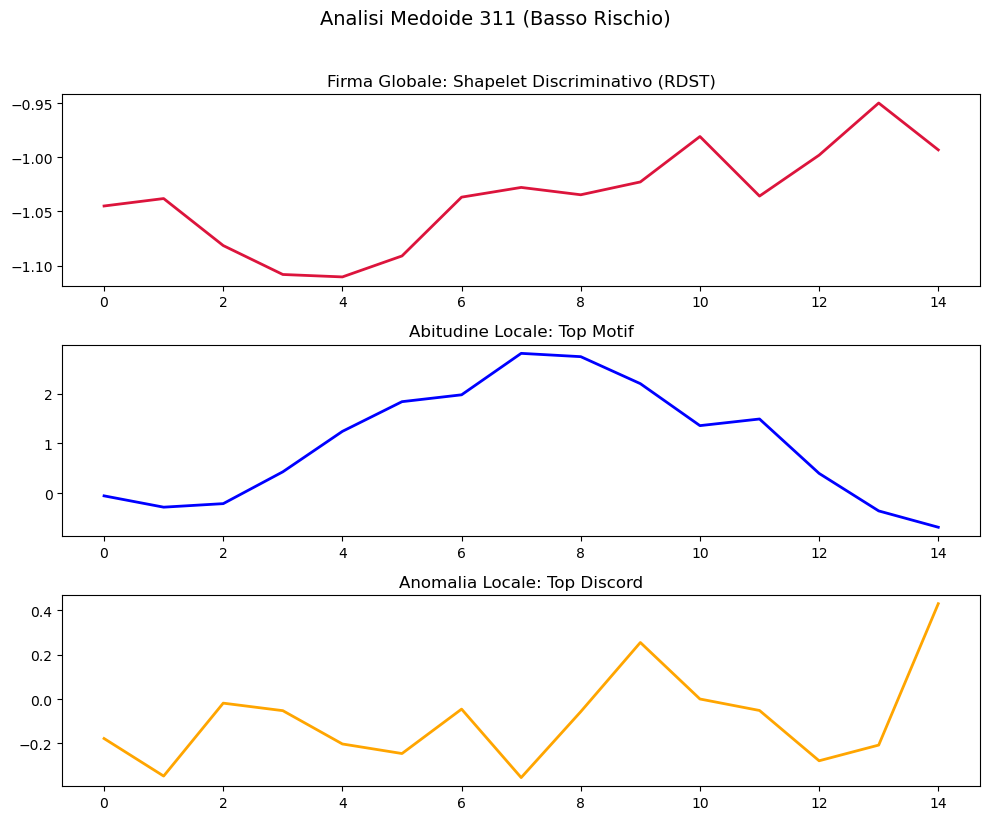

In [9]:
import stumpy
import numpy as np
import matplotlib.pyplot as plt

if 'shapelet_fase_b' in locals() and shapelet_fase_b is not None:
    # Utilizziamo le specifiche Time Series considerate nel modulo dei Motifs (i medoidi estratti dal clustering)
    medoid_idx = [1452, 2791, 2734, 311]
    
    m = len(shapelet_fase_b)
    print(f"--- FASE B: Confronto Globale vs Locale ---")
    print(f"Lunghezza Shapelet (Globale) e Finestra Matrix Profile (Locale): m={m}\n")
    
    for idx in medoid_idx:
        ts_esempio = X[idx] # Usiamo X (dataset originale) per rispettare gli indici assoluti
        etichetta = "Alto Rischio" if y[idx] == 1 else "Basso Rischio"
        
        # Calcoliamo il Matrix Profile con stumpy
        mp = stumpy.stump(ts_esempio, m)
        
        # Estraiamo Top Motif e Top Discord
        motif_idx = mp[:, 0].argmin()
        discord_idx = mp[:, 0].argmax()
        
        top_motif = ts_esempio[motif_idx : motif_idx + m]
        top_discord = ts_esempio[discord_idx : discord_idx + m]
        
        # Disegniamo i grafici per questo medoide
        fig, axs = plt.subplots(3, 1, figsize=(10, 8), sharex=False)
        fig.suptitle(f"Analisi Medoide {idx} ({etichetta})", fontsize=14, y=1.02)
        
        axs[0].plot(shapelet_fase_b, color='crimson', linewidth=2)
        axs[0].set_title("Firma Globale: Shapelet Discriminativo (RDST)")
        
        axs[1].plot(top_motif, color='blue', linewidth=2)
        axs[1].set_title(f"Abitudine Locale: Top Motif")
        
        axs[2].plot(top_discord, color='orange', linewidth=2)
        axs[2].set_title(f"Anomalia Locale: Top Discord")
        
        plt.tight_layout()
        plt.show()
else:
    print("Impossibile eseguire la comparazione: Shapelet non estratto correttamente da RDST.")


### Commento ai Risultati (Shapelets vs Motifs)

In questa fase abbiamo unito i risultati estratti globalmente (Shapelet) con quelli estratti localmente (Motifs/Discords) per i medoidi individuati nel modulo precedente. Seguendo le guidelines del progetto, analizziamo e confrontiamo questi due approcci.

1. **Differenza Concettuale tra i Pattern**:
    * **Shapelet (Crimson)**: Rappresenta un pattern discriminativo a livello *globale*. È la firma del comportamento che massimizza la separazione tra i cluster o le classi (es. Alto vs Basso Rischio) su tutta l'interezza del dataset. Non deve necessariamente essere frequente.
    * **Motif (Blue)**: Rappresenta il pattern *locale* più frequente all'interno della singola serie temporale (il comportamento abitudinario del singolo utente).
    * **Discord (Orange)**: Rappresenta il pattern *locale* più anomalo e unico all'interno della singola serie temporale.

2. **Interpretazione del Confronto Visivo e dei Risultati**:
    Analizzando i plot dei medoidi, possiamo osservare in che misura la "firma globale" (Shapelet) si sovrapponga alle routine quotidiane (Motifs) o alle eccezioni (Discords) dei pazienti rappresentativi.
    * **Similitudine con il Motif**: Se per un medoide ad Alto Rischio lo shapelet presenta una morfologia molto simile al suo Top Motif, significa che il sintomo o il marker comportamentale del rischio per quell'utente si manifesta nella sua *abitudine più consolidata*. Il rischio è dato dalla routine.
    * **Similitudine con il Discord**: Se invece lo shapelet assomiglia di più al Top Discord, indica che il comportamento discriminante per quel paziente si manifesta come una *crisi isolata* o un picco anomalo di attività non abitudinaria.
    * **Confronto tra le Classi**: Osservando i medoidi a Basso Rischio, ci aspetteremmo che la forma dello shapelet non si allinei perfettamente né col Motif né col Discord, evidenziando l'assenza del pattern patologico tipico e giustificando la classificazione del Decision Tree.

In conclusione, la combinazione di Classificazione (Shapelets) e Matrix Profile (Motifs/Discords) ci permette di avere una visione completa: l'RDST ci indica *cosa* cercare per distinguere le classi, mentre il Matrix Profile ci descrive la natura *abitudinaria o anomala* di quel comportamento all'interno della giornata del singolo individuo.
